# KMOS_COUNT — Data completeness audit

Counts unique galaxy targets across three levels:
1. **Catalog** — every unique target assigned to a KMOS IFU (from the FITS master tables)
2. **Reduced** — targets with a `DATACUBE_COMBINED_*.fits` in either combined-cube directory
3. **Redshift** — targets with an entry in `target_redshifts.csv`

Also counts locally available **raw OBs** (`kmos_ob_sorted_local/`).

A galaxy is identified by `(field, arm_target_id)`, which is the key used in
`target_redshifts.csv` and encoded in every `DATACUBE_COMBINED_*.fits` filename.

In [1]:
import glob, os, csv, re, pathlib, collections
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── paths ───────────────────────────────────────────────────────────────────
ECDFS_TABLE  = pathlib.Path("scripts") / "table_ifus_ECDFS 2.fits"
COSMOS_TABLE = pathlib.Path("scripts") / "table_ifus_COSMOS_Field_exptime.fits"
REDSHIFT_CSV = pathlib.Path("scripts") / "target_redshifts.csv"

COMB_DIRS = ["kmos_proc_and_comb_server"]   # sole final-data directory
RAW_DIR   = "kmos_ob_sorted_local"

# ── skip these non-science DATACUBE filenames ────────────────────────────────
SKIP_RE = re.compile(r"recenter[0-9]+", re.I)

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})

In [2]:
# ── 1. Inspect FITS catalog table columns ───────────────────────────────────
for tbl in [ECDFS_TABLE, COSMOS_TABLE]:
    if not tbl.exists():
        print(f"NOT FOUND: {tbl}")
        continue
    with fits.open(tbl) as hdul:
        t = hdul[1].data
        print(f"\n{'='*60}")
        print(f"{tbl.name}")
        print(f"  Rows: {len(t):,}")
        print(f"  Columns: {t.names}")
        # Show a few example rows
        print(f"  First 3 rows:")
        for i in range(min(3, len(t))):
            row = {c: str(t[c][i]).strip() for c in t.names}
            print(f"    {row}")


table_ifus_ECDFS 2.fits
  Rows: 147,261
  Columns: ['dp_id', 'ifu', 's_ra', 's_dec', 's_posang', 's_filt_name', 's_filt_wlen', 's_guidestar_ra', 's_guidestar_dec', 's_obs_id', 's_run_id', 's_exptime', 'group_id', 's_ra_group', 's_dec_group', 's_ra_std_group', 's_dec_std_group', 's_guidestar_ra_std_group', 's_guidestar_dec_std_group']
  First 3 rows:


    {'dp_id': 'KMOS.2013-09-26T07:19:52.569', 'ifu': '1', 's_ra': '53.14529999999999', 's_dec': '-27.744622222222223', 's_posang': '-0.11611', 's_filt_name': 'YJ', 's_filt_wlen': '1170.0', 's_guidestar_ra': '53.135958', 's_guidestar_dec': '-27.63166', 's_obs_id': '977058', 's_run_id': '60.A-9455(A)', 's_exptime': '300.0', 'group_id': '0', 's_ra_group': '53.14533142076502', 's_dec_group': '-27.74460546448087', 's_ra_std_group': '0.06459076955823428', 's_dec_std_group': '0.03444964074911439', 's_guidestar_ra_std_group': 'nan', 's_guidestar_dec_std_group': 'nan'}
    {'dp_id': 'KMOS.2013-09-26T07:19:52.569', 'ifu': '2', 's_ra': '53.11274583333333', 's_dec': '-27.734630555555558', 's_posang': '-0.11611', 's_filt_name': 'YJ', 's_filt_wlen': '1170.0', 's_guidestar_ra': '53.135958', 's_guidestar_dec': '-27.63166', 's_obs_id': '977058', 's_run_id': '60.A-9455(A)', 's_exptime': '300.0', 'group_id': '1', 's_ra_group': '53.11274583333333', 's_dec_group': '-27.734630555555558', 's_ra_std_group': '

    {'dp_id': 'KMOS.2013-01-30T04:44:44.251', 'ifu': '1', 's_ra': '150.14349166666665', 's_dec': '2.26843', 's_posang': '-0.00637', 's_filt_name': 'YJ', 's_filt_wlen': '1170.0', 's_guidestar_ra': '150.153679', 's_guidestar_dec': '2.39929', 's_obs_id': '200258152', 's_run_id': '60.A-9239(B)', 's_exptime': '600.0', 'group_id': '0', 's_ra_group': '150.14349166666668', 's_dec_group': '2.268430000000001', 's_ra_std_group': '1.023181295217353e-10', 's_dec_std_group': '3.197442310920451e-12', 's_guidestar_ra_std_group': '94.25372551388797', 's_guidestar_dec_std_group': '101.06199432832379'}
    {'dp_id': 'KMOS.2013-01-30T04:44:44.251', 'ifu': '2', 's_ra': '150.12229999999997', 's_dec': '2.2791383333333335', 's_posang': '-0.00637', 's_filt_name': 'YJ', 's_filt_wlen': '1170.0', 's_guidestar_ra': '150.153679', 's_guidestar_dec': '2.39929', 's_obs_id': '200258152', 's_run_id': '60.A-9239(B)', 's_exptime': '600.0', 'group_id': '1', 's_ra_group': '150.12229999999997', 's_dec_group': '2.279138333333

In [3]:
# ── 2. Load FITS catalog tables → unique group_ids + per-OB IFU assignments ─

# group_id → set of (dp_id, ifu) pairs (= how many OB-slots this galaxy has)
gid_slots   = collections.defaultdict(set)
# group_id → metadata
gid_meta    = {}    # {gid: {'field': ..., 'n_slots': ..., 'bands': set(), ...}}
# (dp_id, ifu) → group_id  (for cross-referencing)
slot_to_gid = {}

# Track which columns exist (tables may differ)
_NAME_COLS = ["arm_name", "arm_target_id", "target_name",
              "target_id", "targ_name", "name",
              "s_targ_name", "ob_name",
              "arm_object", "object"]

def _find_name_col(names):
    names_lower = [n.lower() for n in names]
    for cand in _NAME_COLS:
        if cand in names_lower:
            return names[names_lower.index(cand)]
    return None

def _find_field_col(names):
    for cand in ["field", "ob_target_name", "target_field", "obs_name"]:
        if cand in [n.lower() for n in names]:
            return names[[n.lower() for n in names].index(cand)]
    return None

def _find_band_col(names):
    for cand in ["s_filt_name", "band", "filter", "grat"]:
        if cand in [n.lower() for n in names]:
            return names[[n.lower() for n in names].index(cand)]
    return None

for tbl_path, field_hint in [
    (ECDFS_TABLE,  "cdfs"),
    (COSMOS_TABLE, "cosmos"),
]:
    if not tbl_path.exists():
        print(f"NOT FOUND: {tbl_path}")
        continue
    with fits.open(tbl_path) as hdul:
        t      = hdul[1].data
        names  = list(t.names)
        n_col  = _find_name_col(names)
        f_col  = _find_field_col(names)
        b_col  = _find_band_col(names)
        print(f"{tbl_path.name}: name_col={n_col!r} field_col={f_col!r} band_col={b_col!r}")

        for i in range(len(t)):
            dp_id = str(t['dp_id'][i]).strip()
            ifu   = int(t['ifu'][i])
            gid   = int(t['group_id'][i])
            band  = str(t[b_col][i]).strip() if b_col else "?"
            field = str(t[f_col][i]).strip().lower() if f_col else field_hint
            tname = str(t[n_col][i]).strip() if n_col else ""

            slot = (dp_id, ifu)
            gid_slots[gid].add(slot)
            slot_to_gid[slot] = gid
            if gid not in gid_meta:
                gid_meta[gid] = {
                    'field':  field or field_hint,
                    'tname':  tname,
                    'bands':  set(),
                    'table':  tbl_path.name,
                }
            gid_meta[gid]['bands'].add(band)
            if tname and not gid_meta[gid]['tname']:
                gid_meta[gid]['tname'] = tname

n_cat = len(gid_meta)
n_obs_slots = sum(len(v) for v in gid_slots.values())
print(f"\nCatalog summary:")
print(f"  Unique group_ids (galaxies): {n_cat:,}")
print(f"  Total IFU-OB slots:          {n_obs_slots:,}")
bands_all = set(b for m in gid_meta.values() for b in m['bands'])
print(f"  Bands observed: {sorted(bands_all)}")

table_ifus_ECDFS 2.fits: name_col=None field_col=None band_col='s_filt_name'


table_ifus_COSMOS_Field_exptime.fits: name_col=None field_col=None band_col='s_filt_name'



Catalog summary:
  Unique group_ids (galaxies): 2,189
  Total IFU-OB slots:          266,990
  Bands observed: ['H', 'HK', 'IZ', 'K', 'YJ']


In [4]:
# ── 3. Scan DATACUBE_COMBINED_*.fits in kmos_proc_and_comb_server ────────────
#
# Filenames do NOT contain a band suffix (e.g. DATACUBE_COMBINED_cosmos_101639.fits).
# Band is read from the FITS header: ESO INS FILT1 NAME.

_BAND_SUFFIX = re.compile(r"_(IZ|YJ|HK|H|K)$")

def _band_from_header(fp):
    """Read band from primary FITS header (ESO INS FILT1 NAME)."""
    try:
        with fits.open(fp, memmap=False) as hdul:
            val = str(hdul[0].header.get("ESO INS FILT1 NAME", "")).strip()
            return val if val else "?"
    except Exception:
        return "?"

# All reduced cubes: key = (stem_no_band, band) → list of file paths
reduced_files = collections.defaultdict(list)
reduced_stems = set()

for cdir in COMB_DIRS:
    pattern = os.path.join(cdir, "**", "DATACUBE_COMBINED_*.fits")
    for fp in sorted(glob.glob(pattern, recursive=True)):
        fn   = os.path.basename(fp)
        stem = fn[len("DATACUBE_COMBINED_"):].replace(".fits", "")
        # Try band from filename first; fall back to FITS header
        m = _BAND_SUFFIX.search(stem)
        if m:
            band        = m.group(1)
            stem_noband = stem[:m.start()]
        else:
            stem_noband = stem
            band        = _band_from_header(fp)
        if SKIP_RE.search(stem_noband):
            continue
        reduced_files[(stem_noband, band)].append(fp)
        reduced_stems.add(stem_noband)

n_comb_unique = len(reduced_stems)
n_comb_total  = len(reduced_files)

print(f"Combined cubes found in {COMB_DIRS}:")
print(f"  Unique targets (any band): {n_comb_unique:,}")
print(f"  Unique (target, band) combos: {n_comb_total:,}")

band_counts = collections.Counter(band for (stem, band) in reduced_files.keys())
print(f"  Band breakdown: {dict(sorted(band_counts.items()))}")

for cdir in COMB_DIRS:
    in_dir = {stem for (stem, band), paths in reduced_files.items()
              if any(cdir in p for p in paths)}
    print(f"  In {cdir}: {len(in_dir):,} unique targets")

print(f"\nExample target stems:")
for s in sorted(reduced_stems)[:15]:
    bands = sorted({band for (st, band) in reduced_files.keys() if st == s})
    print(f"  {s}  [{', '.join(bands)}]")

Combined cubes found in ['kmos_proc_and_comb_server']:
  Unique targets (any band): 199
  Unique (target, band) combos: 273
  Band breakdown: {'H': 41, 'IZ': 110, 'YJ': 122}
  In kmos_proc_and_comb_server: 199 unique targets

Example target stems:
  SPT2040_Halpha_B1  [H]
  SPT2040_Halpha_B2  [H]
  SPT2040_Halpha_B3  [H]
  SPT2040_Halpha_B4  [H]
  SPT2040_Halpha_B6  [H]
  SPT2040_Halpha_B7  [H]
  SPT2040_Halpha_B9  [H]
  SPT2040_Halpha_H128R  [H]
  SPT2040_Halpha_H129R  [H]
  SPT2040_Halpha_H15  [H]
  SPT2040_Halpha_H17  [H]
  SPT2040_Halpha_H20  [H]
  SPT2040_Halpha_H25  [H]
  SPT2040_Halpha_H28  [H]
  SPT2040_Halpha_H30  [H]


In [5]:
# ── 4. Load target_redshifts.csv ────────────────────────────────────────────
z_table = {}    # (field, arm_target_id) → {'z': ..., 'z_type': ..., 'quality': ...}

if REDSHIFT_CSV.exists():
    with open(REDSHIFT_CSV, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            if not (row.get("redshift") or "").strip():
                continue
            key = (row["field"].strip().lower(), row["arm_target_id"].strip())
            z_table[key] = {
                'z':       float(row["redshift"]),
                'z_type':  row.get("redshift_type", "").strip(),
                'quality': row.get("quality", "").strip(),
                'source':  row.get("source_catalog", "").strip(),
            }
    print(f"Redshift catalog: {len(z_table):,} entries")
    types = collections.Counter(v['z_type'] for v in z_table.values())
    print(f"  By type: {dict(sorted(types.items()))}")
    fields = collections.Counter(k[0] for k in z_table.keys())
    print(f"  By field: {dict(sorted(fields.items()))}")
else:
    print(f"NOT FOUND: {REDSHIFT_CSV}")

# Build a set of arm_target_ids (without field) for easy cross-matching
z_ids_by_field = collections.defaultdict(set)
for (field, tid) in z_table.keys():
    z_ids_by_field[field].add(tid)

Redshift catalog: 178 entries
  By type: {'cluster': 16, 'photo': 1, 'spec': 161}
  By field: {'cdfs_targets_2.cat': 22, 'cosmos': 22, 'cosmos_0.6_0.8_h21.4.cat': 19, 'cosmos_0.6_0.8_h21.7.cat': 19, 'cosmos_target_1.cat': 20, 'cosmos_target_legac.cat': 20, 'goods_0.6_0.8_h21.6_lir.cat': 15, 'spt2040_hbeta_oiii': 21, 'xmm2215_empower.cat': 20}


In [6]:
# ── 5. Count locally available raw OBs ──────────────────────────────────────
raw_obs = []
if os.path.isdir(RAW_DIR):
    for entry in sorted(os.scandir(RAW_DIR), key=lambda e: e.name):
        if entry.is_dir():
            fits_in_ob = glob.glob(os.path.join(entry.path, "*.fits"))
            n_science  = sum(1 for f in fits_in_ob
                            if os.path.basename(f).startswith("KMOS."))
            raw_obs.append({'ob': entry.name, 'n_files': len(fits_in_ob), 'n_science': n_science})

print(f"Raw OBs in {RAW_DIR}/: {len(raw_obs)}")
for ob in raw_obs:
    print(f"  {ob['ob']}  ({ob['n_science']} science frames, {ob['n_files']} total files)")

# Also check backup dir for partially processed OBs
BACKUP_DIRS = ["kmos_ob_proc_server_BACKUP", "kmos_ob_proc_server_BACKUP_MEETINGS"]
for bdir in BACKUP_DIRS:
    if os.path.isdir(bdir):
        sub = sorted([d for d in os.scandir(bdir) if d.is_dir()], key=lambda d: d.name)
        print(f"\n{bdir}/: {len(sub)} OB directories")
        for d in sub[:5]:
            print(f"  {d.name}")
        if len(sub) > 5:
            print(f"  ... ({len(sub)-5} more)")

Raw OBs in kmos_ob_sorted_local/: 1
  KMOS.2026-01-12T053655.243  (42 science frames, 43 total files)

kmos_ob_proc_server_BACKUP/: 143 OB directories
  KMOS.2026-01-12T05-36-55.243
  KMOS.2026-01-12T06-45-08.816
  KMOS.2026-01-12T07-43-30.915
  KMOS.2026-01-12T08-40-54.192
  KMOS.2026-01-12T09-16-07.233
  ... (138 more)

kmos_ob_proc_server_BACKUP_MEETINGS/: 48 OB directories
  KMOS.2026-01-12T05-36-55.243
  KMOS.2026-01-12T06-45-08.816
  KMOS.2026-01-12T07-43-30.915
  KMOS.2026-01-12T08-40-54.192
  KMOS.2026-01-12T09-16-07.233
  ... (43 more)


In [7]:
# ── 6. Cross-match: reduced stems ↔ redshift catalog ────────────────────────
#
# Match by arm_target_id (source_id) alone — field naming between CSV and stems
# is inconsistent. Compound CSV IDs like "R_28" are also indexed under their
# last segment "28", so stems where rsplit gives source_id="28" still match.

def _parse_stem(stem):
    """Return (field_hint, catalog, source_id) for a DATACUBE stem."""
    parts = stem.rsplit("_", 1)
    catalog, source_id = (parts if len(parts) == 2 else (stem, stem))
    cl = catalog.lower()
    if   "cosmos" in cl:                               field = "cosmos"
    elif "cdfs" in cl or "ecdfs" in cl or "goods" in cl: field = "cdfs"
    elif "xmm"  in cl:                                field = "xmm2215"
    elif "spt"  in cl:                                field = "spt2040"
    else:                                              field = cl.split("_")[0]
    return field, catalog, source_id

# Build source_id → list of z_table keys
sid_to_zkeys = collections.defaultdict(list)
for (fld, tid) in z_table.keys():
    sid_to_zkeys[tid].append((fld, tid))
    sid_to_zkeys[tid.lstrip("0")].append((fld, tid))
    # Compound IDs like "R_28" → also index last segment "28"
    last_part = tid.rsplit("_", 1)[-1]
    if last_part != tid:
        sid_to_zkeys[last_part].append((fld, tid))

# Per-stem parse and z-match
stem_parsed   = {}
stem_has_z    = {}
stem_z_info   = {}
field_counter = collections.Counter()

for stem in reduced_stems:
    field, catalog, source_id = _parse_stem(stem)
    stem_parsed[stem] = (field, catalog, source_id)
    field_counter[field] += 1

    candidates = (sid_to_zkeys.get(source_id, [])
                  + sid_to_zkeys.get(source_id.lstrip("0"), []))
    found = None
    for (fld, tid) in candidates:
        found = z_table[(fld, tid)]
        break

    stem_has_z[stem]  = found is not None
    stem_z_info[stem] = found

n_reduced_with_z    = sum(stem_has_z.values())
n_reduced_without_z = len(reduced_stems) - n_reduced_with_z

print(f"Reduced targets by field:")
for field, cnt in sorted(field_counter.items()):
    z_ct = sum(1 for s in reduced_stems
               if stem_parsed[s][0] == field and stem_has_z[s])
    print(f"  {field:<20} {cnt:>4} targets   ({z_ct} have redshift)")

print(f"\nReduced targets with redshift:    {n_reduced_with_z:>4}")
print(f"Reduced targets WITHOUT redshift: {n_reduced_without_z:>4}")

Reduced targets by field:
  cdfs                   37 targets   (37 have redshift)
  cosmos                100 targets   (100 have redshift)
  spt2040                42 targets   (42 have redshift)
  xmm2215                20 targets   (20 have redshift)

Reduced targets with redshift:     199
Reduced targets WITHOUT redshift:    0


In [8]:
# ── 7. Cross-match: catalog group_ids ↔ reduced stems ────────────────────────
#
# The FITS tables use group_id; the combined-cube filenames use (catalog, source_id).
# We try to link them: for each group_id, see if its target-name token
# appears in any reduced stem.
#
# This match is best-effort — naming conventions vary across fields.

# Build lookup: source_id → set of stems
source_id_to_stems = collections.defaultdict(set)
for stem, (field, catalog, source_id) in stem_parsed.items():
    source_id_to_stems[source_id].add(stem)
    # Also try without leading zeros
    source_id_to_stems[source_id.lstrip("0")].add(stem)

gid_is_reduced = {}
gid_is_z       = {}

for gid, meta in gid_meta.items():
    tname = meta.get('tname', '').strip()
    field = meta.get('field', '').lower()

    # Try matching by target name token
    matched_stems = set()
    if tname:
        matched_stems = source_id_to_stems.get(tname, set())
        if not matched_stems:
            matched_stems = source_id_to_stems.get(tname.lstrip("0"), set())

    gid_is_reduced[gid] = len(matched_stems) > 0

    # Check redshift
    has_z = False
    if tname:
        for fld_try in [field, field.split("_")[0]]:
            if (fld_try, tname) in z_table:
                has_z = True
                break
    gid_is_z[gid] = has_z

n_gid_reduced  = sum(gid_is_reduced.values())
n_gid_z        = sum(gid_is_z.values())
n_gid_both     = sum(gid_is_reduced[g] and gid_is_z[g] for g in gid_meta)
n_gid_neither  = sum(not gid_is_reduced[g] and not gid_is_z[g] for g in gid_meta)

print(f"Catalog group_id match summary (N={n_cat}):")
print(f"  - Matched to a reduced cube: {n_gid_reduced:>4}")
print(f"  - Have a redshift:           {n_gid_z:>4}")
print(f"  - Both:                      {n_gid_both:>4}")
print(f"  - Neither:                   {n_gid_neither:>4}")
print()
print(f"NOTE: group_id ↔ stem matching relies on target names stored in the")
print(f"      FITS tables; if name column is missing the match count is 0.")

Catalog group_id match summary (N=2189):
  - Matched to a reduced cube:    0
  - Have a redshift:              0
  - Both:                         0
  - Neither:                   2189

NOTE: group_id ↔ stem matching relies on target names stored in the
      FITS tables; if name column is missing the match count is 0.


In [9]:
# ── 8. Master summary table ──────────────────────────────────────────────────

print("="*65)
print("  KMOS DATA COMPLETENESS AUDIT")
print("="*65)
print()

# A. File-system view (most reliable)
print("A) FILE-SYSTEM COUNTS (direct, field-by-field)")
print("-"*65)

by_field = collections.defaultdict(lambda: {'n': 0, 'bands': collections.Counter(),
                                            'n_with_z': 0, 'stems': set()})
for stem, (field, catalog, source_id) in stem_parsed.items():
    by_field[field]['n'] += 1
    by_field[field]['stems'].add(stem)
    if stem_has_z[stem]:
        by_field[field]['n_with_z'] += 1
for (stem, band) in reduced_files.keys():
    field = stem_parsed[stem][0]
    by_field[field]['bands'][band] += 1

_FMT = "{:<24} {:>8} {:>10} {:>14}  {}"
print(_FMT.format("Field", "N_reduced", "N_with_z", "N_with_z (%)", "Bands"))
print("-"*65)
total_r, total_z = 0, 0
for field in sorted(by_field.keys()):
    d    = by_field[field]
    nr   = d['n']
    nz   = d['n_with_z']
    pct  = f"{100*nz/nr:.0f}%" if nr else "-"
    bstr = "+".join(sorted(d['bands'].keys()))
    print(_FMT.format(field, nr, nz, pct, bstr))
    total_r += nr
    total_z += nz
print("-"*65)
pct_tot = f"{100*total_z/total_r:.0f}%" if total_r else "-"
print(_FMT.format("TOTAL", total_r, total_z, pct_tot, ""))
print()

# B. Redshift catalog view
print("B) REDSHIFT CATALOG (target_redshifts.csv)")
print("-"*65)
z_by_field = collections.Counter(k[0] for k in z_table.keys())
z_by_type  = collections.Counter(v['z_type'] for v in z_table.values())
print(_FMT.format("Field", "N_with_z", "", "", "by type"))
print("-"*65)
for fld in sorted(z_by_field.keys()):
    types_in_field = collections.Counter(
        v['z_type'] for k, v in z_table.items() if k[0] == fld)
    tstr = "  ".join(f"{t}:{n}" for t, n in sorted(types_in_field.items()))
    print(_FMT.format(fld, z_by_field[fld], "", "", tstr))
print("-"*65)
tstr_all = "  ".join(f"{t}:{n}" for t, n in sorted(z_by_type.items()))
print(_FMT.format("TOTAL", len(z_table), "", "", tstr_all))
print()

# C. Catalog group_id view
if n_cat > 0:
    print("C) FITS CATALOG (group_id → IFU assignment)")
    print("-"*65)
    print(f"  Total unique group_ids (galaxies observed): {n_cat:,}")
    print(f"  Total IFU-OB slots (rows in tables):        {n_obs_slots:,}")
    obs_per_gal = n_obs_slots / n_cat if n_cat else 0
    print(f"  Average OB-slots per galaxy:                {obs_per_gal:.1f}")
    print(f"  NOTE: covers ALL programs in these fields,")
    print(f"        not only this survey's targets.")
    print()

# D. Raw data
print("D) RAW DATA (locally available)")
print("-"*65)
print(f"  Raw OBs in {RAW_DIR}/: {len(raw_obs)}")
for bdir in BACKUP_DIRS:
    if os.path.isdir(bdir):
        n_backup = len([d for d in os.scandir(bdir) if d.is_dir()])
        print(f"  OBs in {bdir}/: {n_backup}")
print()

# E. Three-way overlap (reduced ∩ redshift) — using source_id matching
print("E) REDUCED vs. REDSHIFT (from file-system view)")
print("-"*65)

# z-entries that have a matching reduced cube (by source_id)
z_keys_covered = set()
for stem in reduced_stems:
    field, cat, sid = stem_parsed[stem]
    for try_sid in [sid, sid.lstrip("0")]:
        for (zfld, ztid) in sid_to_zkeys.get(try_sid, []):
            z_keys_covered.add((zfld, ztid))

print(f"  Reduced (unique targets):             {len(reduced_stems):>5}")
print(f"  Reduced + have redshift:              {n_reduced_with_z:>5}")
print(f"  Reduced + NO redshift:                {n_reduced_without_z:>5}")
print(f"  Redshift entries (total in CSV):      {len(z_table):>5}")
print(f"  z-entries matched to reduced cube:    {len(z_keys_covered):>5}")
print(f"  z-entries NOT yet reduced:            {len(z_table)-len(z_keys_covered):>5}")
print("="*65)

  KMOS DATA COMPLETENESS AUDIT

A) FILE-SYSTEM COUNTS (direct, field-by-field)
-----------------------------------------------------------------
Field                    N_reduced   N_with_z   N_with_z (%)  Bands
-----------------------------------------------------------------
cdfs                           37         37           100%  IZ
cosmos                        100        100           100%  IZ+YJ
spt2040                        42         42           100%  H+YJ
xmm2215                        20         20           100%  H+YJ
-----------------------------------------------------------------
TOTAL                         199        199           100%  

B) REDSHIFT CATALOG (target_redshifts.csv)
-----------------------------------------------------------------
Field                    N_with_z                            by type
-----------------------------------------------------------------
cdfs_targets_2.cat             22                            spec:22
cosmos          

In [10]:
# ── 9. Targets with redshift but NO combined cube yet ────────────────────────
print("TARGETS WITH REDSHIFT BUT NOT YET REDUCED:")
print("-"*70)
_FMT2 = "{:<8}  {:<30}  {:>6}  {:>8}  {}"
print(_FMT2.format("field", "arm_target_id", "z", "z_type", "source"))
print("-"*70)

# Build set of (field, source_id) pairs that ARE reduced
reduced_pairs = set()
for stem, (field, cat, sid) in stem_parsed.items():
    reduced_pairs.add((field, sid))
    reduced_pairs.add((field.split("_")[0], sid))

missing = []
for (field, tid), zinfo in sorted(z_table.items()):
    if (field, tid) not in reduced_pairs and (field.split("_")[0], tid) not in reduced_pairs:
        missing.append((field, tid, zinfo))

for field, tid, zinfo in missing:
    print(_FMT2.format(
        field[:8], tid[:30], f"{zinfo['z']:.4f}",
        zinfo['z_type'], zinfo['source'][:25]))
print(f"\nTotal: {len(missing)} targets have a redshift but no combined cube")

# Also: reduced targets without redshift (per-field)
print()
print("REDUCED TARGETS WITH NO REDSHIFT (by field):")
print("-"*70)
no_z_by_field = collections.defaultdict(list)
for stem in sorted(reduced_stems):
    if not stem_has_z[stem]:
        field, cat, sid = stem_parsed[stem]
        no_z_by_field[field].append(sid)
for field in sorted(no_z_by_field.keys()):
    ids = no_z_by_field[field]
    print(f"  {field:<20}: {len(ids):>3} targets → {', '.join(sorted(ids)[:8])}"
          + (f" ... (+{len(ids)-8} more)" if len(ids) > 8 else ""))

TARGETS WITH REDSHIFT BUT NOT YET REDUCED:
----------------------------------------------------------------------
field     arm_target_id                        z    z_type  source
----------------------------------------------------------------------
goods_0.  10368                           0.6710      spec  astrodeep_gs43
goods_0.  10372                           0.7370      spec  astrodeep_gs43
goods_0.  12408                           0.6710      spec  astrodeep_gs43
goods_0.  12984                           0.6640      spec  astrodeep_gs43
goods_0.  16593                           0.7370      spec  astrodeep_gs43
goods_0.  3901                            0.5860      spec  astrodeep_gs43
goods_0.  4433                            0.7610      spec  astrodeep_gs43
goods_0.  5338                            0.7830      spec  astrodeep_gs43
goods_0.  5426                            0.6360      spec  astrodeep_gs43
goods_0.  5513                            0.7610      spec  astrodeep_gs4

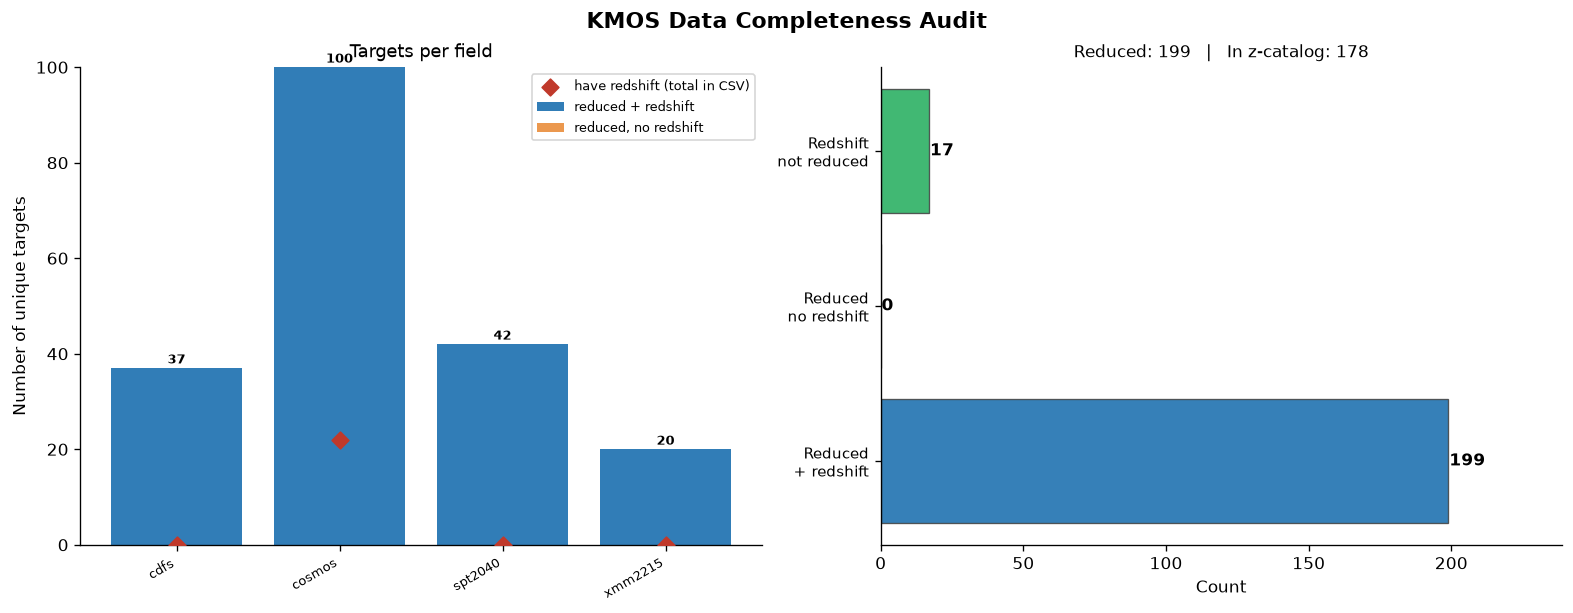

Saved → kmos_count_summary.pdf / .png


In [11]:
# ── 10. Summary figure ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
fig.suptitle("KMOS Data Completeness Audit", fontsize=13, fontweight='bold')

# LEFT: bar chart — counts by field
ax = axes[0]
fields_sorted = sorted(by_field.keys())
x  = np.arange(len(fields_sorted))
n_red_arr  = [by_field[f]['n']       for f in fields_sorted]
n_z_arr    = [by_field[f]['n_with_z'] for f in fields_sorted]
n_noz_arr  = [n - z for n, z in zip(n_red_arr, n_z_arr)]

bars_z   = ax.bar(x, n_z_arr,    color="#1a6faf", alpha=0.9, label="reduced + redshift")
bars_noz = ax.bar(x, n_noz_arr, bottom=n_z_arr, color="#e67e22", alpha=0.8,
                  label="reduced, no redshift")

for xi, (nz, nr) in enumerate(zip(n_z_arr, n_red_arr)):
    ax.text(xi, nr + 0.3, str(nr), ha='center', va='bottom', fontsize=8, fontweight='bold')

# Add redshift-catalog total for each field (dots)
z_totals = [z_by_field.get(f, 0) for f in fields_sorted]
ax.scatter(x, z_totals, marker='D', s=50, color='#c0392b', zorder=5,
           label="have redshift (total in CSV)")

ax.set_xticks(x)
ax.set_xticklabels(fields_sorted, rotation=30, ha='right', fontsize=8)
ax.set_ylabel("Number of unique targets")
ax.set_title("Targets per field", fontsize=11)
ax.legend(fontsize=8, framealpha=0.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# RIGHT: stacked summary pie / bar
ax2 = axes[1]
categories = [
    ("Reduced\n+ redshift",  n_reduced_with_z,    "#1a6faf"),
    ("Reduced\nno redshift", n_reduced_without_z,  "#e67e22"),
    ("Redshift\nnot reduced", len(missing),          "#27ae60"),
]
labels = [c[0] for c in categories]
sizes  = [c[1] for c in categories]
colors = [c[2] for c in categories]

bars = ax2.barh(range(len(categories)), sizes, color=colors, alpha=0.88, edgecolor='#444', lw=0.8)
for bi, (bar, sz) in enumerate(zip(bars, sizes)):
    ax2.text(sz + 0.3, bi, str(sz), va='center', fontsize=10, fontweight='bold')
ax2.set_yticks(range(len(categories)))
ax2.set_yticklabels(labels, fontsize=9)
ax2.set_xlabel("Count")
ax2.set_title(
    f"Reduced: {len(reduced_stems)}   |   In z-catalog: {len(z_table)}",
    fontsize=10)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xlim(0, max(sizes) * 1.2 if sizes else 10)

plt.savefig("kmos_count_summary.pdf", bbox_inches='tight')
plt.savefig("kmos_count_summary.png", bbox_inches='tight', dpi=150)
plt.show()
print("Saved → kmos_count_summary.pdf / .png")

In [12]:
# ── 11. Full detail table of all reduced targets ─────────────────────────────
print(f"{'stem':<50}  {'band(s)':<12}  {'has_z':>5}  {'z':>7}  z_type")
print("-"*95)
for stem in sorted(reduced_stems):
    bands = sorted({band for (st, band) in reduced_files.keys() if st == stem})
    hz    = stem_has_z[stem]
    zi    = stem_z_info.get(stem)
    z_str = f"{zi['z']:.4f}" if zi else "-"
    zt    = zi['z_type'] if zi else "-"
    print(f"{stem:<50}  {'+'.join(bands):<12}  {str(hz):>5}  {z_str:>7}  {zt}")

stem                                                band(s)       has_z        z  z_type
-----------------------------------------------------------------------------------------------
SPT2040_Halpha_B1                                   H              True   1.4760  spec
SPT2040_Halpha_B2                                   H              True   1.4777  spec
SPT2040_Halpha_B3                                   H              True   1.4842  spec
SPT2040_Halpha_B4                                   H              True   1.4765  spec
SPT2040_Halpha_B6                                   H              True   1.4800  spec
SPT2040_Halpha_B7                                   H              True   1.4808  spec
SPT2040_Halpha_B9                                   H              True   1.4782  spec
SPT2040_Halpha_H128R                                H              True   1.4786  cluster
SPT2040_Halpha_H129R                                H              True   1.4786  cluster
SPT2040_Halpha_H15        